# Homework 8.1 - Task 9

## The Merging Singularity

At the final time,

$$
\alpha(1)=0
$$

and

$$
\sigma(1)=1.
$$

The two component distributions become identical standard Gaussians.

The resulting density is perfectly regular.

The singularity is in the representation and in the chosen forward SDE coefficients, not in the final probability density.

## 1. Score limit

The exact score is

$$
s(x,t)
=
\frac{
m(t)
\tanh\left(
\frac{m(t)x}{v(t)}
\right)
-x
}{
v(t)
}.
$$

As $t$ approaches 1,

$$
m(t)\to 0
$$

and

$$
v(t)\to 1.
$$

Therefore

$$
s(x,t)\to -x.
$$

The endpoint score is exactly the score of the standard Gaussian.

## 2. Responsibility limit

The positive-component responsibility is

$$
r_+(x,t)
=
\frac{1}{2}
\left[
1+
\tanh\left(
\frac{m(t)x}{v(t)}
\right)
\right].
$$

Thus

$$
r_+(x,t)\to \frac{1}{2}.
$$

At the endpoint, observing $x$ gives no information about which of the two identical latent component labels generated it.

In [9]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(config["a"])
Q = float(config["q"])

In [10]:
def alpha(t):
    return np.cos(
        0.5
        * np.pi
        * np.asarray(
            t,
            dtype=float,
        )
    )


def variance(t):
    a = alpha(t)

    return (
        1.0
        - Q
        * a**2
    )


def normal_density(
    x,
    mean,
    var,
):
    return (
        np.exp(
            -0.5
            * (x - mean)**2
            / var
        )
        / np.sqrt(
            2.0
            * np.pi
            * var
        )
    )


def mixture_density(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * normal_density(
            x,
            -m,
            v,
        )
        + 0.5
        * normal_density(
            x,
            m,
            v,
        )
    )


def standard_normal_density(
    x,
):
    return normal_density(
        x,
        0.0,
        1.0,
    )


def score(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        m
        * np.tanh(
            m * x / v
        )
        - x
    ) / v


def responsibility_plus(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * (
            1.0
            + np.tanh(
                m * x / v
            )
        )
    )


def forward_probability_flow_velocity(
    x,
    t,
):
    theta = (
        0.5
        * np.pi
        * t
    )

    a_t = np.cos(
        theta
    )

    v_t = (
        1.0
        - Q
        * a_t**2
    )

    return (
        np.pi
        * np.sin(
            theta
        )
        / (2.0 * v_t)
        * (
            Q
            * a_t
            * x
            - A
            * np.tanh(
                A
                * a_t
                * x
                / v_t
            )
        )
    )

## 3. Quantify information loss

On a fixed grid we track:

- density distance from the standard Gaussian;
- score distance from $-x$;
- responsibility distance from $1/2$;
- stabilized probability-flow speed.

We also compute the mutual information between the latent component label $Z$ and $X_t$.

For equal prior component probabilities,

$$
I(Z;X_t)
=
\log 2
-
E[
H(r_+(X_t,t))
].
$$

Here

$$
H(r)
=
-r\log r
-
(1-r)\log(1-r).
$$

At the final time, this mutual information is zero.

In [11]:
x_grid = np.linspace(
    -8.0,
    8.0,
    200_001,
)

times = [
    0.0,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.999,
    1.0,
]

standard_density = (
    standard_normal_density(
        x_grid
    )
)

rows = []

for t in times:
    p = mixture_density(
        x_grid,
        t,
    )

    s = score(
        x_grid,
        t,
    )

    r = responsibility_plus(
        x_grid,
        t,
    )

    velocity = (
        forward_probability_flow_velocity(
            x_grid,
            t,
        )
    )

    r_clipped = np.clip(
        r,
        1e-15,
        1.0 - 1e-15,
    )

    entropy = (
        -r_clipped
        * np.log(
            r_clipped
        )
        - (
            1.0
            - r_clipped
        )
        * np.log(
            1.0
            - r_clipped
        )
    )

    conditional_entropy = (
        np.trapz(
            p * entropy,
            x_grid,
        )
    )

    mutual_information = (
        np.log(2.0)
        - conditional_entropy
    )

    rows.append({
        "t": t,
        "alpha": float(
            alpha(t)
        ),
        "variance": float(
            variance(t)
        ),
        "density_L1_distance_to_standard_normal": float(
            np.trapz(
                np.abs(
                    p
                    - standard_density
                ),
                x_grid,
            )
        ),
        "max_abs_score_difference_from_minus_x": float(
            np.max(
                np.abs(
                    s
                    + x_grid
                )
            )
        ),
        "max_abs_responsibility_deviation_from_half": float(
            np.max(
                np.abs(
                    r
                    - 0.5
                )
            )
        ),
        "latent_label_mutual_information_nats": float(
            max(
                0.0,
                mutual_information,
            )
        ),
        "max_abs_stabilized_probability_flow_velocity": float(
            np.max(
                np.abs(
                    velocity
                )
            )
        ),
    })


merging_table = pd.DataFrame(
    rows
)

merging_path = (
    DATA_DIR
    / "task9_merging_singularity_diagnostics.csv"
)

merging_table.to_csv(
    merging_path,
    index=False,
)

print(
    merging_table.to_string(
        index=False
    )
)

    t        alpha  variance  density_L1_distance_to_standard_normal  max_abs_score_difference_from_minus_x  max_abs_responsibility_deviation_from_half  latent_label_mutual_information_nats  max_abs_stabilized_probability_flow_velocity
0.000 1.000000e+00  0.062500                            1.697341e+00                              88.000000                                5.000000e-01                          6.931472e-01                                  0.000000e+00
0.250 9.238795e-01  0.199794                            1.397126e+00                              22.792968                                5.000000e-01                          6.930943e-01                                  1.483013e+01
0.500 7.071068e-01  0.531250                            7.967761e-01                               4.396774                                5.000000e-01                          6.240662e-01                                  6.906437e+00
0.750 3.826834e-01  0.862706                            

## 4. Plot latent-label information loss

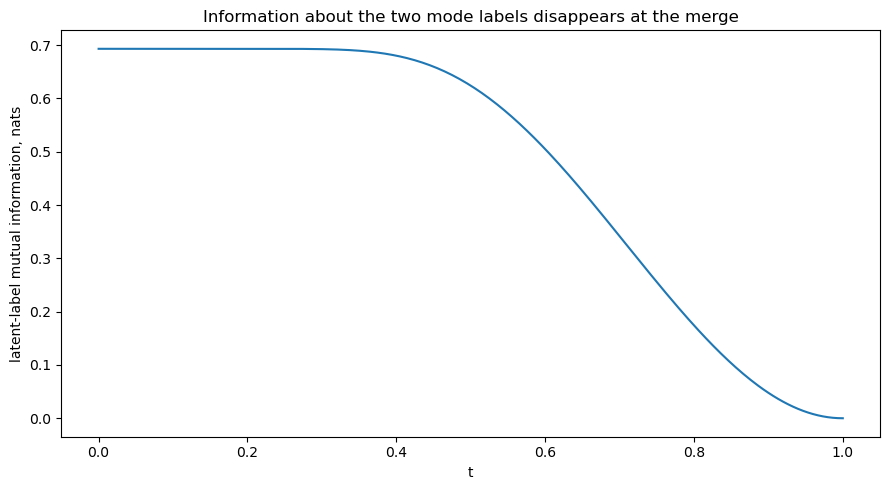

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task9_latent_label_information.png


In [12]:
fine_times = np.linspace(
    0.0,
    1.0,
    300,
)

mi_values = []

for t in fine_times:
    p = mixture_density(
        x_grid,
        t,
    )

    r = responsibility_plus(
        x_grid,
        t,
    )

    r_clipped = np.clip(
        r,
        1e-15,
        1.0 - 1e-15,
    )

    entropy = (
        -r_clipped
        * np.log(
            r_clipped
        )
        - (
            1.0
            - r_clipped
        )
        * np.log(
            1.0
            - r_clipped
        )
    )

    conditional_entropy = (
        np.trapz(
            p * entropy,
            x_grid,
        )
    )

    mi_values.append(
        max(
            0.0,
            np.log(2.0)
            - conditional_entropy,
        )
    )


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    fine_times,
    mi_values,
)

plt.xlabel("t")
plt.ylabel(
    "latent-label mutual information, nats"
)
plt.title(
    "Information about the two mode labels disappears at the merge"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task9_latent_label_information.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

## 5. Plot convergence of the score

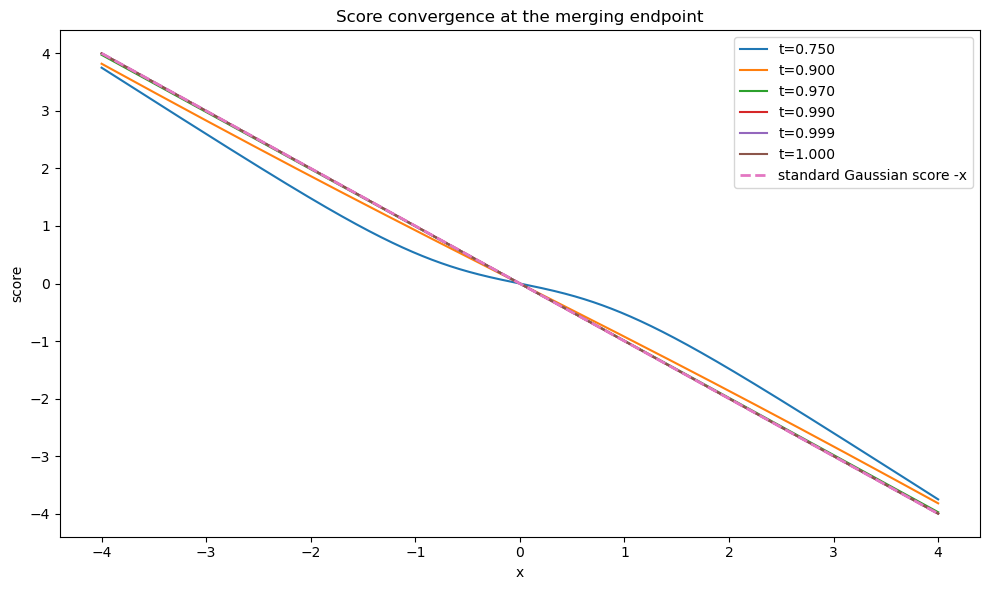

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task9_score_endpoint_convergence.png


In [13]:
selected_times = [
    0.75,
    0.90,
    0.97,
    0.99,
    0.999,
    1.0,
]

x_plot = np.linspace(
    -4.0,
    4.0,
    3000,
)

plt.figure(
    figsize=(10, 6)
)

for t in selected_times:
    plt.plot(
        x_plot,
        score(
            x_plot,
            t,
        ),
        label=f"t={t:.3f}",
    )

plt.plot(
    x_plot,
    -x_plot,
    linestyle="--",
    linewidth=2.0,
    label="standard Gaussian score -x",
)

plt.xlabel("x")
plt.ylabel("score")
plt.title(
    "Score convergence at the merging endpoint"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task9_score_endpoint_convergence.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 9 Interpretation

The endpoint contains three different phenomena.

## Density

The density remains smooth and converges to the standard Gaussian.

There is no density singularity.

## Chosen SDE coefficients

The finite-time schedule makes $b(t)$ and $g(t)^2$ diverge as $t$ approaches 1.

This is a schedule-dependent coefficient singularity.

After analytic cancellation, the probability-flow velocity has a continuous endpoint extension.

## Mixture representation

The two Gaussian components become identical.

The posterior responsibilities converge to $1/2$, and the latent-label mutual information converges to zero.

Therefore the two-component parametrization is no longer identifiable.

The same final density could be written as one standard Gaussian, two identical Gaussians with arbitrary weights, or many identical copies.

This is a representation singularity, not a singularity of the probability density.